This notebook provides an example use case for `tdhelper`.

Let's work with sptPALM data of Dynamin-1bb isoform tagged with mEos2 (Dyn1bb-mEos2) expressed within PC12 cells (Jiang et al., 2024).
We recommend working with python environments, and have installed `tdhelper` in this environment (see README.md).

First, lets do our imports:

In [25]:
# tdhelper is built around the TrajectoryData class
from tdhelper.core import TrajectoryData

# for some plots
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np


Now, lets load our data:

In [31]:
pixel_size = 0.106 # specify the pixel size of our acquisition (in microns)
DT = 0.02 # specify the time interval between frames (in seconds)

# we are using a .txt file generated from PALMTracer
fname = "data\\dyn1bb_ctrl_1_stream1_trcPALMTracer.txt" # specify the path to the .txt file

spt_data = TrajectoryData()
spt_data.import_trc(fname, pixel_size)

# trajectory data is stored in a pandas dataframe, which can be accessed via the `data` attribute
# tr is the trajectory ID, x and y are the coordinates (in microns), and t is the time (in frames)
print(spt_data.data.head())

# you can have a look at how many trajectories there are by checking the number of unique trajectory IDs
print('# trajectories in the dataset: {}'.format(len(spt_data.data['tr'].unique())))


   tr          x         y  t
0   1  19.730050  2.585148  1
1   1  19.725796  2.579739  2
2   1  19.726968  2.577252  3
3   1  19.724272  2.580609  4
4   1  19.729369  2.588638  5
# trajectories in the dataset: 1912


Lets have a look at what the trajectories look like:

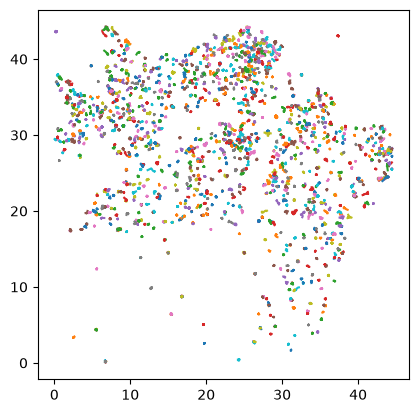

In [27]:
fig, ax = plt.subplots()
spt_data.plot_trajectories(ax=ax)

Let's use matplotlib's functionality to have a closer look:

(20.0, 30.0)

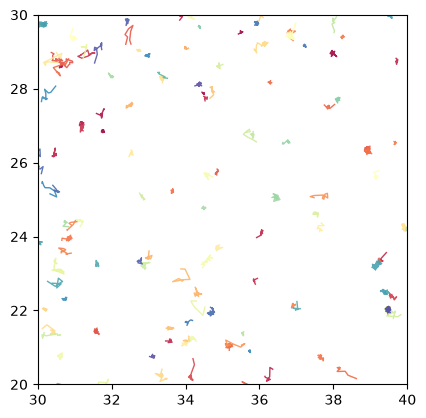

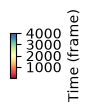

In [28]:
fig, ax = plt.subplots()
spt_data.plot_trajectories(ax=ax, color_by_time=True, cmap='Spectral', alpha=0.9, linewidth=1)
ax.set_xlim(30, 40)
ax.set_ylim(20, 30)

Lets analyse the trajectories within this region:

# of trajectories: 147


C:\Users\uqkkudo\Documents\python_projects\tdhelper\src\tdhelper\_plotting.py:539: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  sem_values[i] = sem(vector)


median Dapp: 0.00522044853686294
mean Dapp: 0.05049754223697419


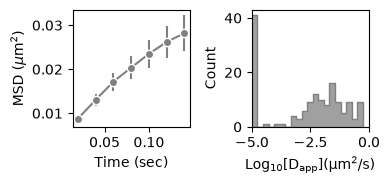

In [ ]:
# filter by those trajectories whose centroid is within this region
spt_data.filter_by_centroid(xmin=30, xmax=40, ymin=20, ymax=30)

# lets see how many trajectories we have in this region:
print('# of trajectories: {}'.format(len(spt_data.data.tr.unique())))

spt_data.calc_MSD()
spt_data.calc_diffusion_coefficient(DT)

# the MSD data and diffusion coefficient data are stored in the `msd_dict` and `diff_list` attributes
# so they can be accessed directly and stored in bigger dictionaries if you are looping through multiple datasets:
# spt_data.msd_dict
# spt_data.diff_list

# create a matplotlib figure that we can plot onto
fig, ax = plt.subplots(1, 2, figsize=(4,2), layout='tight')

# plotting the MSD
spt_data.plot_mean_msds(ax[0], DT=DT, color='grey', plot_x_limit=8) # you'll get a warning here because it will try to calculate SEM with only one trajectory at the longest lag-times

# plotting the diffusion coefficient distribution, lets use seaborn
sns.histplot(np.log10(spt_data.diff_list), stat='count', bins=20, color='grey', ax=ax[1], element='step')
ax[1].set_xlim(-5, 0)
ax[1].set_xlabel(r'$\mathrm{Log_{10}[D_{app}] (\mu m^2/s}$)')
ax[1].set_box_aspect(1)

print('median Dapp: {}'.format(np.median(spt_data.diff_list)))
print('mean Dapp: {}'.format(np.mean(spt_data.diff_list)))


Lets plot the trajectories again, but this time colour by diffusion coefficient:

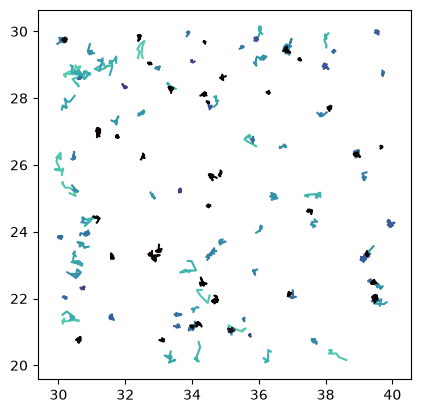

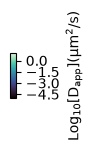

In [30]:
fig, ax = plt.subplots()
spt_data.plot_trajectories_diff_v2(ax=ax, palette='mako')